In [1]:
#%pip install uproot lz4 xxhash
import uproot

import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from matplotlib.colors import LogNorm

In [2]:
# open root file and list the TTrees it contains
file = uproot.open("myPET.root")
file.keys()

['Hits;25',
 'Hits;24',
 'Singles;9',
 'Singles;8',
 'latest_event_ID;1',
 'total_nb_primaries;1',
 'OpticalData;1',
 'Coincidences;1']

## Singles -- energy depositions in each crystal

In [3]:
# Let's load the Singles and see the structure
# This structure stores information about the hits is each of the crystals
singles = file["Singles"]
singles.keys()
#singles.show()

['runID',
 'eventID',
 'sourceID',
 'sourcePosX',
 'sourcePosY',
 'sourcePosZ',
 'time',
 'energy',
 'globalPosX',
 'globalPosY',
 'globalPosZ',
 'gantryID',
 'rsectorID',
 'moduleID',
 'submoduleID',
 'crystalID',
 'layerID',
 'comptonPhantom',
 'comptonCrystal',
 'RayleighPhantom',
 'RayleighCrystal',
 'axialPos',
 'rotationAngle',
 'comptVolName',
 'RayleighVolName']

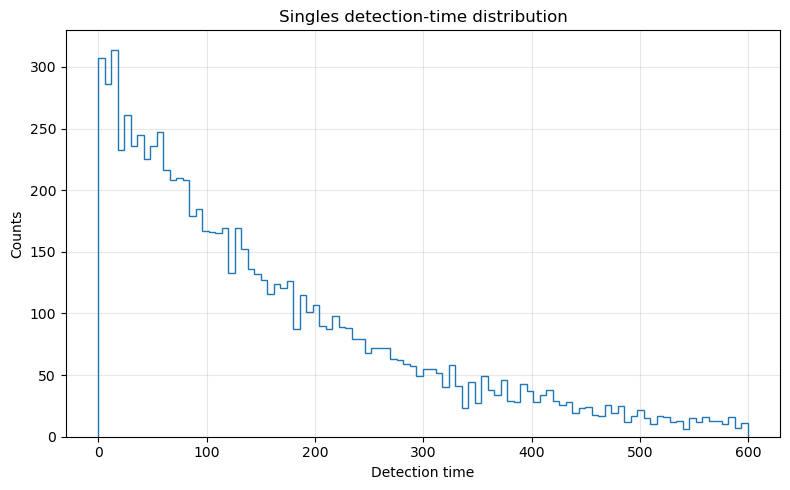

In [4]:
# Time distribution
time = singles["time"].array(library="np")

plt.figure(figsize=(8, 5))
plt.hist(time, bins=100, histtype="step")

plt.xlabel("Detection time")
plt.ylabel("Counts")
plt.title("Singles detection-time distribution")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

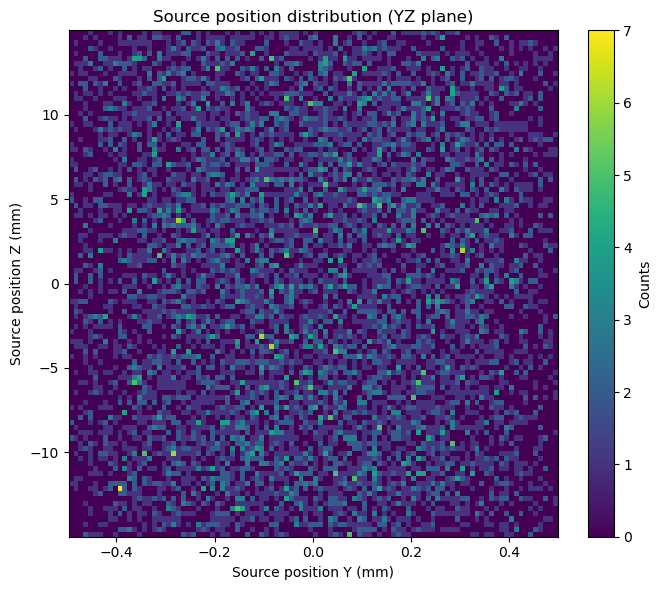

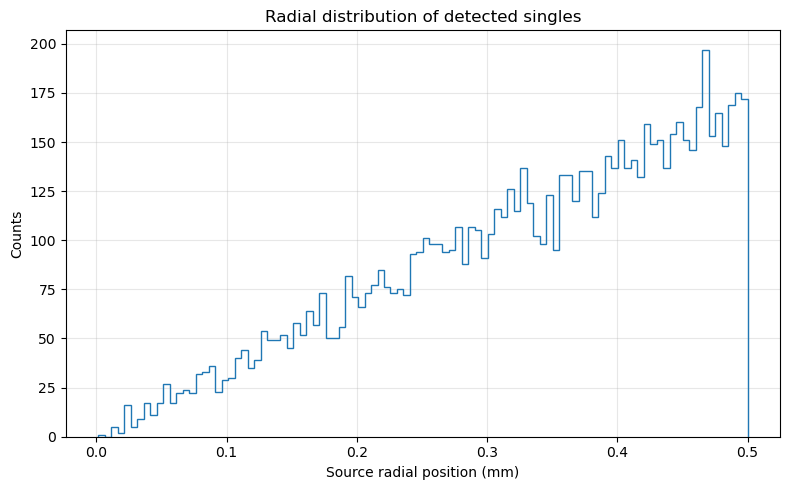

In [5]:
# Initial positions of the detected gammas
source_x = singles["sourcePosX"].array(library="np")
source_y = singles["sourcePosY"].array(library="np")
source_z = singles["sourcePosZ"].array(library="np")

plt.figure(figsize=(7, 6))
plt.hist2d(source_y, source_z, bins=100)
plt.xlabel("Source position Y (mm)")
plt.ylabel("Source position Z (mm)")
plt.title("Source position distribution (YZ plane)")
plt.colorbar(label="Counts")
plt.tight_layout()
plt.show()

source_r = np.sqrt(source_x**2 + source_y**2)

plt.figure(figsize=(8, 5))
plt.hist(source_r, bins=100, histtype="step")
plt.xlabel("Source radial position (mm)")
plt.ylabel("Counts")
plt.title("Radial distribution of detected singles")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

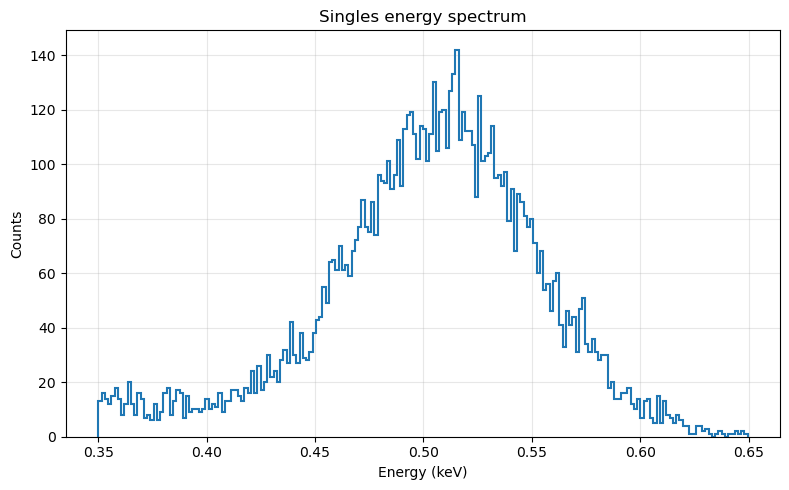

In [6]:
# Energy
energy = singles["energy"].array(library="np")

plt.figure(figsize=(8, 5))

plt.hist(energy, bins=200, histtype="step", linewidth=1.5)

plt.xlabel("Energy (keV)")
plt.ylabel("Counts")
plt.title("Singles energy spectrum")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Peak mean: 0.50909
Gaussian sigma: 0.042556
Relative energy resolution (FWHM/mean): 19.69%


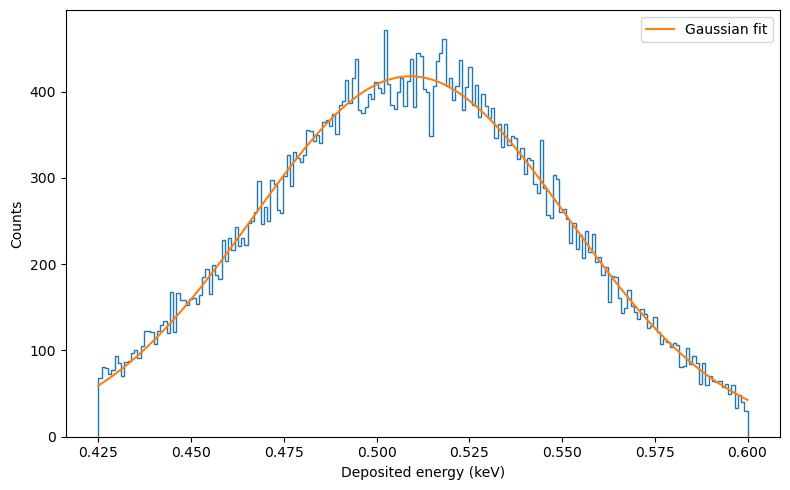

In [28]:
# Let's do a Gaussian fit to this spectrum

# Choose a fitting interval around the photopeak
fit_min = 0.425  # Replace with the appropriate lower bound
fit_max = 0.60  # Replace with the appropriate upper bound

counts, edges = np.histogram(
    energy, bins=200, range=(fit_min, fit_max)
)
centres = (edges[:-1] + edges[1:]) / 2

def gaussian(x, amplitude, mean, sigma):
    return amplitude * np.exp(-0.5 * ((x - mean) / sigma)**2)

# Use bin centres with nonzero counts
p0 = [counts.max(), centres[np.argmax(counts)], 0.02]
parameters, covariance = curve_fit(
    gaussian, centres, counts, p0=p0
)

amplitude, mean, sigma = parameters
mean_error, sigma_error = np.sqrt(np.diag(covariance))[1:3]

resolution = 2.355 * abs(sigma) / abs(mean) * 100

print(f"Peak mean: {mean:.5g}")
print(f"Gaussian sigma: {abs(sigma):.5g}")
print(f"Relative energy resolution (FWHM/mean): {resolution:.2f}%")

plt.figure(figsize=(8, 5))
plt.hist(energy, bins=200, range=(fit_min, fit_max), histtype="step")
xfit = np.linspace(fit_min, fit_max, 500)
plt.plot(xfit, gaussian(xfit, *parameters), label="Gaussian fit")
plt.xlabel("Deposited energy (keV)")
plt.ylabel("Counts")
plt.legend()
plt.tight_layout()
plt.show()

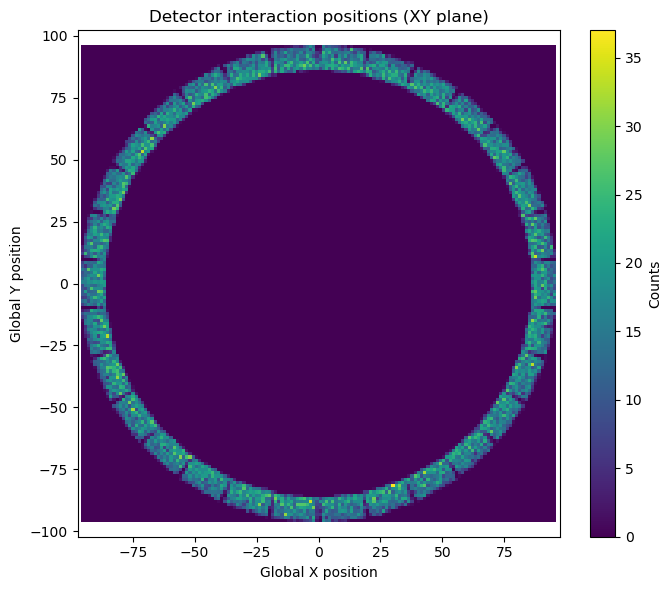

In [30]:
# Interaction positions (XY plane)

x = singles["globalPosX"].array(library="np")
y = singles["globalPosY"].array(library="np")
z = singles["globalPosZ"].array(library="np")

plt.figure(figsize=(7, 6))
plt.hist2d(x, y, bins=150)
plt.xlabel("Global X position")
plt.ylabel("Global Y position")
plt.title("Detector interaction positions (XY plane)")
plt.colorbar(label="Counts")
plt.axis("equal")
plt.tight_layout()
plt.show()

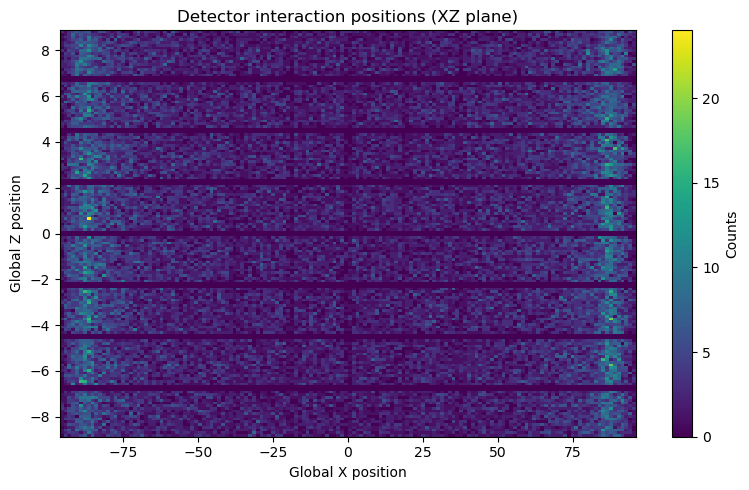

In [33]:
# Interaction positions (XZ plane)

plt.figure(figsize=(8, 5))
plt.hist2d(x, z, bins=150)
plt.xlabel("Global X position")
plt.ylabel("Global Z position")
plt.title("Detector interaction positions (XZ plane)")
plt.colorbar(label="Counts")
plt.tight_layout()
plt.show()

## Coincidences -- two crystals with interactions in the same event

In [5]:
# And now the Coincidences TTrees
# This structure stores information on the coincidences, i.e.,
# when at least two crystals detect energy in the same event
coincidences = file["Coincidences"]
coincidences.keys()

['runID',
 'axialPos',
 'rotationAngle',
 'eventID1',
 'sourceID1',
 'sourcePosX1',
 'sourcePosY1',
 'sourcePosZ1',
 'time1',
 'energy1',
 'globalPosX1',
 'globalPosY1',
 'globalPosZ1',
 'gantryID1',
 'rsectorID1',
 'moduleID1',
 'submoduleID1',
 'crystalID1',
 'layerID1',
 'comptonPhantom1',
 'comptonCrystal1',
 'RayleighPhantom1',
 'RayleighCrystal1',
 'eventID2',
 'sourceID2',
 'sourcePosX2',
 'sourcePosY2',
 'sourcePosZ2',
 'time2',
 'energy2',
 'globalPosX2',
 'globalPosY2',
 'globalPosZ2',
 'gantryID2',
 'rsectorID2',
 'moduleID2',
 'submoduleID2',
 'crystalID2',
 'layerID2',
 'comptonPhantom2',
 'comptonCrystal2',
 'RayleighPhantom2',
 'RayleighCrystal2',
 'sinogramTheta',
 'sinogramS',
 'comptVolName1',
 'comptVolName2',
 'RayleighVolName1',
 'RayleighVolName2']

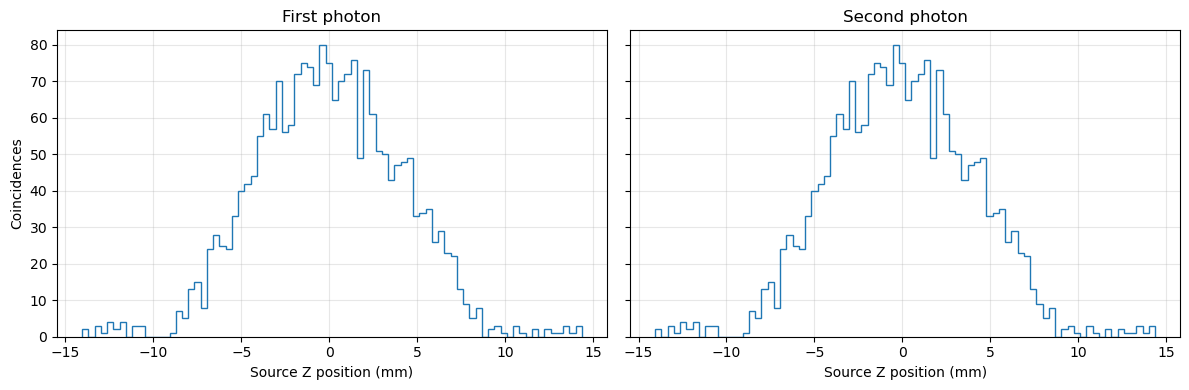

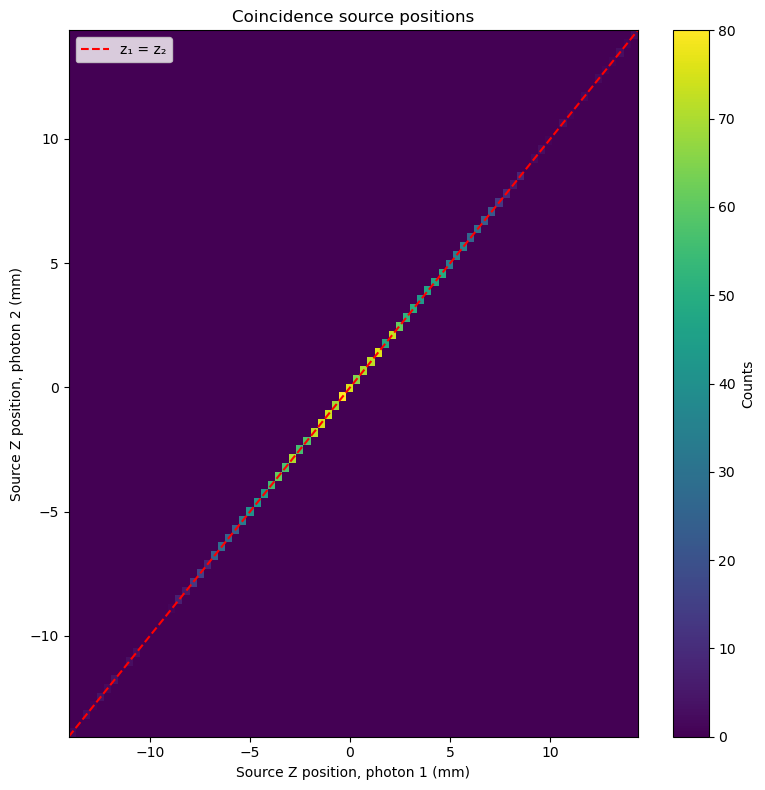

In [38]:
# Source Z positions for each detection
# Should these be exactly identical?

source_z1 = coincidences["sourcePosZ1"].array(library="np")
source_z2 = coincidences["sourcePosZ2"].array(library="np")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

axes[0].hist(source_z1, bins=80, histtype="step")
axes[0].set_title("First photon")
axes[0].set_xlabel("Source Z position (mm)")
axes[0].set_ylabel("Coincidences")

axes[1].hist(source_z2, bins=80, histtype="step")
axes[1].set_title("Second photon")
axes[1].set_xlabel("Source Z position (mm)")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 8))
plt.hist2d(source_z1, source_z2, bins=80)
plt.xlabel("Source Z position, photon 1 (mm)")
plt.ylabel("Source Z position, photon 2 (mm)")
plt.title("Coincidence source positions")
plt.colorbar(label="Counts")

# Reference line: equal source positions
limits = [
    min(source_z1.min(), source_z2.min()),
    max(source_z1.max(), source_z2.max())
]
plt.plot(limits, limits, "r--", label="z₁ = z₂")
plt.legend()
plt.tight_layout()
plt.show()

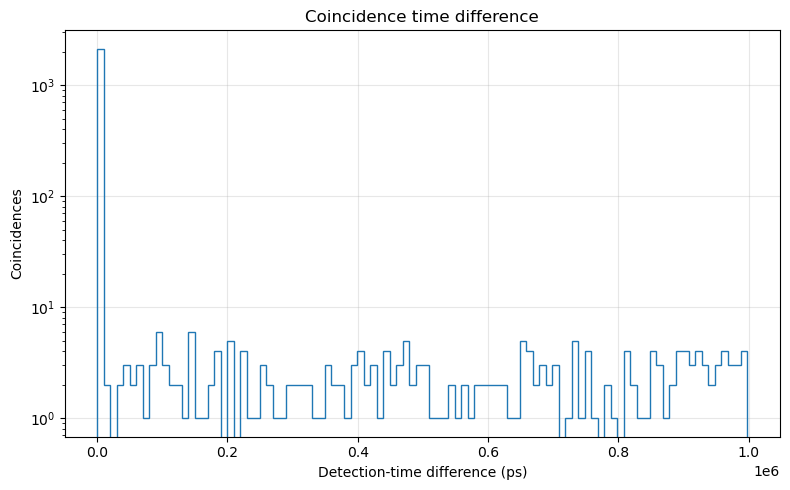

In [7]:
# Time difference between the detections

time1 = coincidences["time1"].array(library="np")
time2 = coincidences["time2"].array(library="np")

# Convert seconds to picoseconds if the stored times are in seconds.
# Verify the time unit in your GATE output before using this conversion.
delta_t = (time2 - time1) * 1e12

plt.figure(figsize=(8, 5))
plt.hist(delta_t, bins=100, histtype="step")
plt.xlabel("Detection-time difference (ps)")
plt.ylabel("Coincidences")
plt.title("Coincidence time difference")
#plt.yscale('log')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

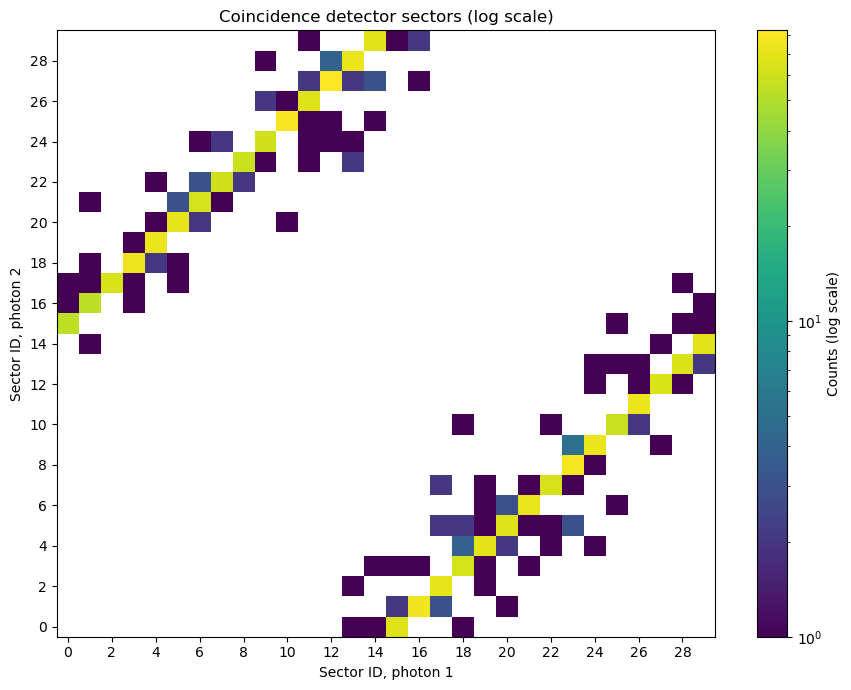

In [45]:
# Check that the gammas are detected back to back

sector1 = coincidences["rsectorID1"].array(library="np")
sector2 = coincidences["rsectorID2"].array(library="np")

bins = np.arange(31) - 0.5

plt.figure(figsize=(9, 7))

plt.hist2d(
    sector1,
    sector2,
    bins=(bins, bins),
    norm=LogNorm(vmin=1),
    cmap="viridis"
)

plt.xlabel("Sector ID, photon 1")
plt.ylabel("Sector ID, photon 2")
plt.title("Coincidence detector sectors (log scale)")
plt.xticks(range(0, 30, 2))
plt.yticks(range(0, 30, 2))
plt.colorbar(label="Counts (log scale)")
plt.tight_layout()
plt.show()

Total coincidences: 2147
Coincidences without phantom scattering: 2042
Fraction without phantom scattering: 0.951


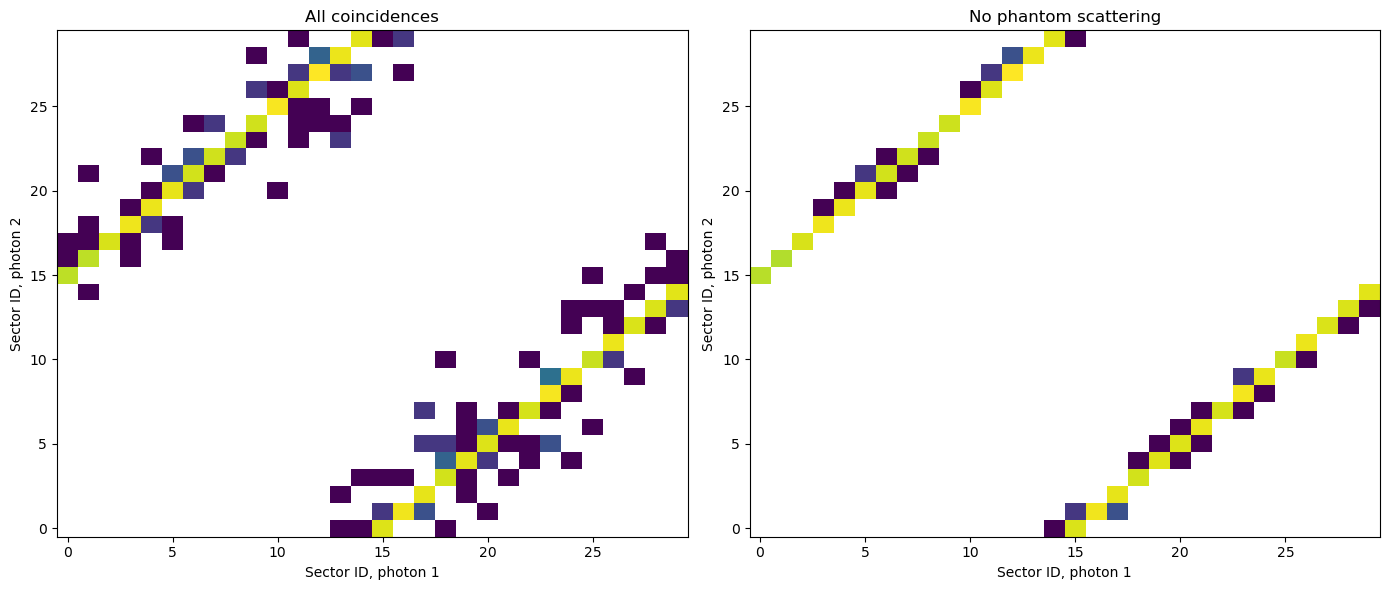

In [46]:
compton1 = coincidences["comptonPhantom1"].array(library="np")
compton2 = coincidences["comptonPhantom2"].array(library="np")

rayleigh1 = coincidences["RayleighPhantom1"].array(library="np")
rayleigh2 = coincidences["RayleighPhantom2"].array(library="np")

# Keep events with no Compton or Rayleigh scattering
# in the phantom for either photon
no_scatter = (
    (compton1 == 0) &
    (compton2 == 0) &
    (rayleigh1 == 0) &
    (rayleigh2 == 0)
)

print(f"Total coincidences: {len(no_scatter)}")
print(f"Coincidences without phantom scattering: {np.sum(no_scatter)}")
print(f"Fraction without phantom scattering: {np.mean(no_scatter):.3f}")


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].hist2d(
    sector1, sector2,
    bins=(bins, bins),
    norm=LogNorm(vmin=1)
)
axes[0].set_title("All coincidences")

axes[1].hist2d(
    sector1[no_scatter], sector2[no_scatter],
    bins=(bins, bins),
    norm=LogNorm(vmin=1)
)
axes[1].set_title("No phantom scattering")

for ax in axes:
    ax.set_xlabel("Sector ID, photon 1")
    ax.set_ylabel("Sector ID, photon 2")
    ax.set_xticks(range(0, 30, 5))
    ax.set_yticks(range(0, 30, 5))

plt.tight_layout()
plt.show()

## Exercises